In [12]:
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt

In [2]:
gate_results = pd.read_csv('results/kl_gate_training.csv')

In [4]:
gate_results.query("n_samples==512 and skip_ratio>0.27").sort_values(by='val_ppl').head(10)
# lrb=1 lrw=0.01 init_skip=0.3 target_skip=0.3
# lrb=1 lrw=0.01 init_skip=0.5 target_skip=0.3

,n_samples,lrb,lrw,run_i,val_ppl,skip_ratio,init_skip,target_skip
320,512.0,1.00,0.1,1.0,11.396168,0.274709,0.3,0.3
335,512.0,0.10,0.1,0.0,11.580521,0.278142,0.3,0.3
374,512.0,1.00,0.1,1.0,11.619710,0.277288,0.5,0.3
373,512.0,1.00,0.1,0.0,11.624618,0.274633,0.5,0.3
319,512.0,1.00,0.1,0.0,11.792731,0.279592,0.3,0.3
336,512.0,0.01,0.1,0.0,11.917892,0.270686,0.3,0.3
382,512.0,0.10,0.1,1.0,11.978439,0.281438,0.5,0.3
300,512.0,10.00,0.1,2.0,11.998688,0.277690,0.3,0.3
299,512.0,10.00,0.1,1.0,12.064742,0.288503,0.3,0.3
298,512.0,10.00,0.1,0.0,13.425131,0.279561,0.3,0.3


In [6]:
distributions = torch.load("results/distributions_evolution_256.pt")

In [9]:
def visualize_dist(gate_store, ax=None, xlabel=True, title="Distribution of decisions"):
    flat = torch.cat([t.reshape(-1) for t in gate_store])
    values = flat.float().detach().cpu().numpy()
    num_unique = len(np.unique(values))
    bins = min(100, num_unique)
    if ax is None: 
        plt.figure(figsize=(6, 3))
        plt.hist(values, bins=bins)
        plt.xlabel("Gate Decision")
        plt.title(title)
        plt.show()
    else:
        ax.hist(values, bins=bins)
        if xlabel: ax.set_xlabel("Gate Decision")
        ax.set_title(title)
        sns.despine()
        ax.spines['left'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['top'].set_visible(False)
        # ax.spines['bottom'].set_visible(False)
        ax.tick_params(axis='y', left=False, labelleft=False)

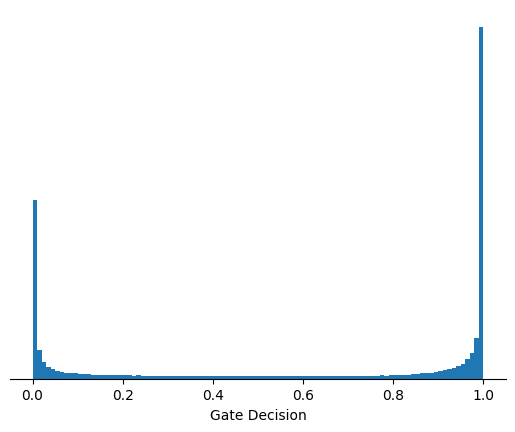

In [15]:
fig, ax = plt.subplots(1, 1)
visualize_dist(distributions[128], ax=ax, xlabel=True, title="")

In [16]:
results_df = pd.read_csv('results/gate_training.csv')

In [17]:
results_df

,lr,target_skip,grad_accum_steps,run_i,val_ppl,skip_ratio,n_samples
0,0.010,0.30,1.0,0.0,40.181728,0.271189,128.0
1,0.010,0.30,1.0,1.0,30.678564,0.277089,128.0
2,0.010,0.30,1.0,2.0,23.993603,0.238632,128.0
3,0.010,0.30,2.0,0.0,68.322548,0.281825,128.0
4,0.010,0.30,2.0,1.0,48.386608,0.268138,128.0
...,...,...,...,...,...,...,...
157,0.005,0.35,2.0,1.0,77.452309,0.307541,512.0
158,0.005,0.35,2.0,2.0,48.694077,0.328211,512.0
159,0.005,0.35,4.0,0.0,38.978367,0.306300,512.0
160,0.005,0.35,4.0,1.0,66.697609,0.307332,512.0
